In [1]:
# Install XGBoost (only needed once). If it is already installed, nothing changes.
%pip install xgboost


   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.5 MB/s eta 0:00:32
    --------------------------------------- 0.8/48.9 MB 1.7 MB/s eta 0:00:29
    --------------------------------------- 0.8/48.9 MB 1.7 MB/s eta 0:00:29
   - -------------------------------------- 1.8/48.9 MB 2.0 MB/s eta 0:00:24
   - -------------------------------------- 2.4/48.9 MB 2.1 MB/s eta 0:00:23
   -- ------------------------------------- 2.9/48.9 MB 2.0 MB/s eta 0:00:23
   -- ------------------------------------- 3.7/48.9 MB 2.3 MB/s eta 0:00:21
   --- ------------------------------------ 3.9/48.9 MB 2.3 MB/s eta 0:00:20
   --- ------------------------------------ 3.9/48.9 MB 2.3 MB/s eta 0:00:20
   --- --------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import the libraries we need
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Show all columns when we print a table
pd.set_option("display.max_columns", 50)

# Path to the data made in Notebook 02, and folder to save models
DATA_PATH = "../data/processed/land_model_data.csv"
MODEL_DIR = "../models/"

# Fixed seed so results are the same every time we run
SEED = 42

# Load the model data
df = pd.read_csv(DATA_PATH)

print("Shape (rows, columns):", df.shape)
print("Missing values:", df.isna().sum().sum())
df.head(3)


Shape (rows, columns): (5376, 39)
Missing values: 0


,Address_ID,Address,date,period,Land_size(Perches),type_residential,type_commercial,type_agricultural,type_other,Distance from fort,count_govtschools_A,min_dist_govtschools_a,count_govtschools_B,min_dist_govtschools_b,count_semigovtschools,min_dist_semigovtschools,count_intlschools,min_dist_intlschools,count_uni,min_dist_uni,min_dist_nearest_express,min_dist_nearest_railway,min_dist_nearest_bank,count_banks_within_2km,min_dist_nearest_FinanceCompany,count_FinanceCompanies_within_2km,min_dist_nearest_Govt_Hospital,count_Govt_Hospitals,min_dist_nearest_Pvt_Hospital,count_Pvt_Hospital,min_dist_nearest_Pvt_Med_center,count_Pvt_Med_Centers,min_dist_nearest_Supermarket,count_Supermarkets_within2km,min_dist_nearest_Fuel_station,count_Fuel_Stations_within2km,Price per Perch,price_adj,log_price_adj
0,18,bope,2023-08-13,2023-H2,10.0,1,0,0,0,36.09,0,18.656149,1,0.546813,0,10.478451,0,21.224113,0,5.192049,16.694409,3.421132,4.421975,0,4.385422,0,15.857647,0,4.668703,0,11.631035,0,4.992931,0,9.219190,0,305000.0,3.557871e+05,12.782088
1,10,thalawathugoda,2025-02-15,2025-H1,27.0,1,1,0,0,14.19,0,3.947032,1,1.741785,0,3.685223,0,2.039184,0,4.333994,4.620078,3.239813,0.047188,14,0.311696,1,4.725444,0,0.346662,1,2.606001,0,0.207307,9,1.832361,1,3146000.0,3.146000e+06,14.961642
2,19,boralesgamuwa,2021-09-16,2021-H2,17.5,1,1,0,0,13.98,0,4.016691,1,0.429339,0,2.727913,0,3.818289,1,1.440498,8.830429,2.212403,0.071858,10,0.087264,2,1.864090,1,4.973745,0,0.811285,1,0.100747,11,0.886449,1,3386000.0,4.858256e+06,15.396190


In [3]:
# Target column: log of the price at the 2025-H1 level
TARGET = "log_price_adj"

# Columns that must NOT be inputs:
# - id and date columns (they only identify the row)
# - the three price columns (they are the answer, or made from the answer)
id_cols = ["Address_ID", "Address", "date", "period"]
price_cols = ["Price per Perch", "price_adj", "log_price_adj"]
drop_cols = id_cols + price_cols

# Inputs (X) and target (y)
X = df.drop(columns=drop_cols)
y = df[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

# Safety check: no price column should be inside X
print("Price columns inside X:", [c for c in price_cols if c in X.columns])

# Show the feature names
print("\nFeatures:")
print(list(X.columns))


X shape: (5376, 32)
y shape: (5376,)
Price columns inside X: []

Features:
['Land_size(Perches)', 'type_residential', 'type_commercial', 'type_agricultural', 'type_other', 'Distance from fort', 'count_govtschools_A', 'min_dist_govtschools_a', 'count_govtschools_B', 'min_dist_govtschools_b', 'count_semigovtschools', 'min_dist_semigovtschools', 'count_intlschools', 'min_dist_intlschools', 'count_uni', 'min_dist_uni', 'min_dist_nearest_express', 'min_dist_nearest_railway', 'min_dist_nearest_bank', 'count_banks_within_2km', 'min_dist_nearest_FinanceCompany', 'count_FinanceCompanies_within_2km', 'min_dist_nearest_Govt_Hospital', 'count_Govt_Hospitals', 'min_dist_nearest_Pvt_Hospital', 'count_Pvt_Hospital', 'min_dist_nearest_Pvt_Med_center', 'count_Pvt_Med_Centers', 'min_dist_nearest_Supermarket', 'count_Supermarkets_within2km', 'min_dist_nearest_Fuel_station', 'count_Fuel_Stations_within2km']


In [4]:
from sklearn.model_selection import train_test_split

# Split rows: 80% for training, 20% kept as the final test set
# The test set is not used in this notebook for any training or tuning
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED)

# Keep the area ids of each part (needed later for validation by area)
groups_train = df.loc[X_train.index, "Address_ID"]
groups_test = df.loc[X_test.index, "Address_ID"]

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train share: {:.1%}".format(len(X_train) / len(X)))

# How many areas are in each part, and how many areas are in both?
a_train, a_test = set(groups_train), set(groups_test)
print("\nAreas in train:", len(a_train))
print("Areas in test :", len(a_test))
print("Test areas that also appear in train:", len(a_test & a_train))

# Compare the target in both parts (they should look similar)
print("\nTarget (log price) summary:")
print(pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(3))


Train: (4300, 32)  Test: (1076, 32)
Train share: 80.0%

Areas in train: 152
Areas in test : 113
Test areas that also appear in train: 111

Target (log price) summary:
          train      test
count  4300.000  1076.000
mean     14.315    14.279
std       1.044     1.033
min      11.513    11.513
25%      13.391    13.374
50%      14.087    14.077
75%      15.104    15.057
max      18.597    18.634


In [5]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Validation inside the 80% training data only (the 20% test set is not touched)
# 5 folds, and rows of the same area always stay together in one fold
# So the validation part always has areas the model did not see in training
cv = GroupKFold(n_splits=5)
cv_splits = list(cv.split(X_train, y_train, groups=groups_train))

# Check the size of each fold
for i, (tr_idx, va_idx) in enumerate(cv_splits, start=1):
    print(f"Fold {i}: train rows = {len(tr_idx)}, validation rows = {len(va_idx)}")

# Helper: score a prediction (y_true and y_pred are log prices)
def score(y_true, y_pred):
    rmse_log = np.sqrt(mean_squared_error(y_true, y_pred))
    mae_log = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    # Go back to Rupees to get an error in percent
    price_true, price_pred = np.exp(y_true), np.exp(y_pred)
    mape = np.mean(np.abs(price_true - price_pred) / price_true) * 100
    return {"RMSE_log": rmse_log, "MAE_log": mae_log, "R2": r2, "MAPE_%": mape}

# Quick test of the helper: a dummy model that always predicts the train mean
dummy = np.full(len(y_test), y_train.mean())
print("\nBaseline (always predict the mean), tested on train mean vs test:")
print({k: round(v, 3) for k, v in score(y_test, dummy).items()})


Fold 1: train rows = 3440, validation rows = 860
Fold 2: train rows = 3440, validation rows = 860
Fold 3: train rows = 3440, validation rows = 860
Fold 4: train rows = 3440, validation rows = 860
Fold 5: train rows = 3440, validation rows = 860

Baseline (always predict the mean), tested on train mean vs test:
{'RMSE_log': np.float64(1.033), 'MAE_log': 0.848, 'R2': -0.001, 'MAPE_%': np.float64(110.758)}


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, cross_val_predict

# Here we store the validation score of every model
results = {}

# Helper: validation score of a model, using out-of-fold predictions on train data
def validate(model):
    pred = cross_val_predict(model, X_train, y_train, cv=cv_splits)
    return score(y_train, pred)

# Baseline on validation: for each fold, predict the mean of that fold's training rows
base_pred = np.zeros(len(y_train))
for tr_idx, va_idx in cv_splits:
    base_pred[va_idx] = y_train.iloc[tr_idx].mean()
results["Baseline (mean)"] = score(y_train, base_pred)

# Ridge needs inputs on the same scale, so we scale first
ridge_pipe = Pipeline([("scale", StandardScaler()), ("ridge", Ridge())])

# Try different alpha values (a bigger alpha means a stronger penalty)
ridge_grid = {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]}
ridge_search = GridSearchCV(ridge_pipe, ridge_grid, cv=cv_splits,
                            scoring="neg_root_mean_squared_error")
ridge_search.fit(X_train, y_train)

print("Best Ridge setting:", ridge_search.best_params_)

# Validation score of the best Ridge
results["Ridge"] = validate(ridge_search.best_estimator_)

print(pd.DataFrame(results).T.round(3))


Best Ridge setting: {'ridge__alpha': 100}
                 RMSE_log  MAE_log     R2   MAPE_%
Baseline (mean)     1.049    0.864 -0.011  109.110
Ridge               0.495    0.340  0.775   41.816


In [7]:
from sklearn.ensemble import RandomForestRegressor

# Settings to try for Random Forest
rf_grid = {
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 3, 5],
    "max_features": [0.33, 0.6, 1.0],
}

# n_jobs=-1 uses all CPU cores to make it faster
rf = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)
rf_search = GridSearchCV(rf, rf_grid, cv=cv_splits,
                         scoring="neg_root_mean_squared_error")
rf_search.fit(X_train, y_train)

print("Best Random Forest setting:", rf_search.best_params_)

# Validation score of the best Random Forest
results["Random Forest"] = validate(rf_search.best_estimator_)

print(pd.DataFrame(results).T.round(3))


Best Random Forest setting: {'max_depth': 10, 'max_features': 1.0, 'min_samples_leaf': 5}
                 RMSE_log  MAE_log     R2   MAPE_%
Baseline (mean)     1.049    0.864 -0.011  109.110
Ridge               0.495    0.340  0.775   41.816
Random Forest       0.498    0.339  0.772   41.497


In [8]:
from xgboost import XGBRegressor

# Settings to try for XGBoost
xgb_grid = {
    "n_estimators": [200, 400],
    "max_depth": [3, 5],
    "learning_rate": [0.03, 0.1],
    "min_child_weight": [1, 5],
    "colsample_bytree": [0.6, 1.0],
}

# subsample=0.8 means each tree sees 80% of the rows (helps against overfitting)
xgb = XGBRegressor(subsample=0.8, random_state=SEED, n_jobs=-1)
xgb_search = GridSearchCV(xgb, xgb_grid, cv=cv_splits,
                          scoring="neg_root_mean_squared_error")
xgb_search.fit(X_train, y_train)

print("Best XGBoost setting:", xgb_search.best_params_)

# Validation score of the best XGBoost
results["XGBoost"] = validate(xgb_search.best_estimator_)

print(pd.DataFrame(results).T.round(3))


Best XGBoost setting: {'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 5, 'min_child_weight': 5, 'n_estimators': 200}
                 RMSE_log  MAE_log     R2   MAPE_%
Baseline (mean)     1.049    0.864 -0.011  109.110
Ridge               0.495    0.340  0.775   41.816
Random Forest       0.498    0.339  0.772   41.497
XGBoost             0.504    0.346  0.767   41.496


        Ridge  Random Forest  XGBoost
Fold 1  0.504          0.497    0.483
Fold 2  0.462          0.445    0.443
Fold 3  0.433          0.463    0.471
Fold 4  0.511          0.525    0.558
Fold 5  0.554          0.553    0.555
Mean    0.493          0.497    0.502
Std     0.047          0.044    0.052


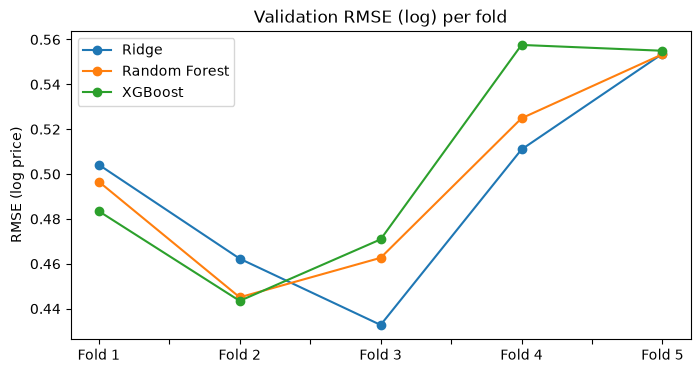

In [9]:
# RMSE (log scale) of each model in each validation fold
models = {
    "Ridge": ridge_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_,
}

fold_rmse = {}
for name, model in models.items():
    scores = []
    for tr_idx, va_idx in cv_splits:
        model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        pred = model.predict(X_train.iloc[va_idx])
        scores.append(np.sqrt(mean_squared_error(y_train.iloc[va_idx], pred)))
    fold_rmse[name] = scores

fold_table = pd.DataFrame(fold_rmse, index=[f"Fold {i}" for i in range(1, 6)])
fold_table.loc["Mean"] = fold_table.mean()
fold_table.loc["Std"] = fold_table.iloc[:5].std()
print(fold_table.round(3))

# Plot: one line per model across the 5 folds
fold_table.iloc[:5].plot(marker="o", figsize=(8, 4),
                         title="Validation RMSE (log) per fold")
plt.ylabel("RMSE (log price)")
plt.show()


In [10]:
import joblib

# Refit each best model on the full 80% training data
for name, model in models.items():
    model.fit(X_train, y_train)

# Save the three fitted models
joblib.dump(models["Ridge"], MODEL_DIR + "ridge_model.joblib")
joblib.dump(models["Random Forest"], MODEL_DIR + "random_forest_model.joblib")
joblib.dump(models["XGBoost"], MODEL_DIR + "xgboost_model.joblib")

# Save the best settings of each model
best_params = {
    "Ridge": ridge_search.best_params_,
    "Random Forest": rf_search.best_params_,
    "XGBoost": xgb_search.best_params_,
}
with open(MODEL_DIR + "best_params.json", "w") as f:
    json.dump(best_params, f, indent=2)

# Save the validation results (area-wise 5-fold, on the 80% training data)
val_table = pd.DataFrame(results).T.round(4)
val_table.to_csv("../reports/tables/03_validation_results.csv")
fold_table.round(4).to_csv("../reports/tables/03_validation_per_fold.csv")

print("Saved models:")
import os
print(sorted(f for f in os.listdir(MODEL_DIR) if f != ".gitkeep"))


Saved models:
['best_params.json', 'random_forest_model.joblib', 'ridge_model.joblib', 'xgboost_model.joblib']


In [11]:
# Save the train and test tables (with area id and date, so Notebook 04 can analyse by area)
keep = ["Address_ID", "Address", "date", "period"]
train_out = df.loc[X_train.index, keep].join(X_train).join(y_train)
test_out = df.loc[X_test.index, keep].join(X_test).join(y_test)
train_out.to_csv("../data/processed/train_80.csv", index=False)
test_out.to_csv("../data/processed/test_20_untouched.csv", index=False)

# Save the split details in one small file
split_info = {
    "source_file": "land_model_data.csv",
    "data_note": "augmented data, calibrated to CBSL LVI, supervisor-approved",
    "target": TARGET,
    "features": list(X.columns),
    "n_features": X.shape[1],
    "split": "random 80/20",
    "seed": SEED,
    "n_train": len(X_train),
    "n_test": len(X_test),
    "train_row_index": [int(i) for i in X_train.index],
    "test_row_index": [int(i) for i in X_test.index],
    "validation": "GroupKFold, 5 folds, grouped by Address_ID, inside the 80% train only",
    "test_areas_also_in_train": len(a_test & a_train),
    "test_areas_total": len(a_test),
}
with open(MODEL_DIR + "split_info.json", "w") as f:
    json.dump(split_info, f)

# Check: reload and confirm train and test do not overlap
tr = pd.read_csv("../data/processed/train_80.csv")
te = pd.read_csv("../data/processed/test_20_untouched.csv")
print("Train:", tr.shape, " Test:", te.shape)
print("Row overlap between train and test:",
      len(set(split_info["train_row_index"]) & set(split_info["test_row_index"])))


Train: (4300, 37)  Test: (1076, 37)
Row overlap between train and test: 0


## Summary of Model Training (Notebook 03)

- Data: `land_model_data.csv` (5,376 rows). Augmented data, calibrated to the CBSL Land Valuation Indicator, supervisor-approved.
- Target: `log_price_adj` (price moved to the 2025-H1 level, then log). 32 input features. Ids, dates and all price columns are not inputs.
- Split: random 80% train (4,300 rows) / 20% final test (1,076 rows), seed 42. The test set was not used for any training or tuning, and is saved for Notebook 04.
- Note: 111 of the 113 test areas also appear in train, so the final random test score will look better than for brand-new areas.
- Validation: 5-fold GroupKFold by area, inside the 80% train only. Each validation fold has areas the model did not see in training.
- Models tuned with grid search: Ridge, Random Forest, XGBoost.
- Validation results (mean RMSE on log price): Ridge 0.493, Random Forest 0.497, XGBoost 0.502. R² is about 0.77 and MAPE about 41.5% for all three. The baseline (mean only) has R² about 0.
- The three models are tied. The gap between them (0.01) is smaller than the change between folds (std about 0.05). No clear winner.
- Random Forest best settings sit at the edge of the grid (max_depth 10, min_samples_leaf 5). A wider grid could be tried later.
- Saved in `models/`: three fitted models, `best_params.json`, `split_info.json`. Saved in `data/processed/`: `train_80.csv`, `test_20_untouched.csv`. Saved in `reports/tables/`: validation results.
- Next: Notebook 04, final evaluation of all three models on the untouched 20% test set.
